# Russia Trade Master All-in-One
## End-to-end structural empirical analysis with tables and figures

이 노트북 하나로 **처음부터 끝까지** 모두 수행합니다.

## 입력 우선순위
1. `Russia_BACI_Lite_Dataset.zip` 이 있으면 우선 사용
2. 없고 `BACI_HS12_V202601.zip` 이 있으면 자동으로 Lite dataset 생성 후 분석

## 자동 탐색 경로
- `/content`
- `/content/BACI`
- `/content/drive/MyDrive/BACI`

## 최종 출력
- 표: CSV + Excel
- 그래프: PNG
- 메타데이터: JSON
- 최종 묶음: `Russia_Trade_Master_Final_Outputs.zip`

## 분석 범위
- T1 Partner-share trajectory
- T2 Concentration: HHI / CR1 / CR3 / Entropy / Effective N
- T3 China specificity
- T4 HS6 product dependence
- T5 Non-energy robustness
- T6 Value vs quantity (HS270900 crude oil to China)
- T7 Bilateral exposure gap
- T8 Structural-break screening
- HS6 statistical inference:
  - Wilcoxon signed-rank
  - Bootstrap 95% CI
  - Sign-flip permutation test
  - Rank-biserial effect size

## 주의
- 인과추론은 수행하지 않습니다.
- 모든 최종 숫자와 그래프는 **하나의 동일 데이터셋** 기준으로 계산됩니다.


In [4]:
!pip -q install pandas numpy scipy matplotlib statsmodels pyarrow openpyxl tqdm

from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import zipfile, shutil, json, warnings
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

ROOT = Path("/content/russia_trade_master")
RAW = ROOT / "raw"
LITE = ROOT / "lite"
OUT = ROOT / "outputs"
TAB = OUT / "tables"
FIG = OUT / "figures"

for p in [RAW, LITE, OUT, TAB, FIG]:
    p.mkdir(parents=True, exist_ok=True)

SEARCH_DIRS = [
    Path("/content"),
    Path("/content/BACI"),
    Path("/content/drive/MyDrive/BACI"),
]


## 1. 입력 파일 탐색 및 Lite dataset 자동 생성

In [5]:
def find_file(name):
    for d in SEARCH_DIRS:
        if d.exists():
            p = d / name
            if p.exists():
                return p
    return None

def mount_drive_if_needed():
    try:
        from google.colab import drive
        drive.mount("/content/drive", force_remount=False)
    except Exception as e:
        print("Drive mount:", e)

lite_zip = find_file("Russia_BACI_Lite_Dataset.zip")
baci_zip = find_file("BACI_HS12_V202601.zip")

if lite_zip is None and baci_zip is None:
    mount_drive_if_needed()
    lite_zip = find_file("Russia_BACI_Lite_Dataset.zip")
    baci_zip = find_file("BACI_HS12_V202601.zip")

print("Found Lite ZIP:", lite_zip)
print("Found BACI ZIP:", baci_zip)


Found Lite ZIP: /content/BACI/Russia_BACI_Lite_Dataset.zip
Found BACI ZIP: None


In [6]:
# Fixed config
BACI_VERSION = "202601"
YEARS = list(range(2015, 2025))
PRE = [2019, 2020, 2021]
ADJUSTMENT_YEAR = 2022
POST = [2023, 2024]

RUS = 643
CHN = 156
IND = 699
TUR = 792
KAZ = 398

EU27 = [
    40,56,100,191,196,203,208,233,246,250,276,300,348,372,
    380,428,440,442,470,528,616,620,642,703,705,724,752
]

if lite_zip is None:
    if baci_zip is None:
        raise FileNotFoundError(
            "Russia_BACI_Lite_Dataset.zip 또는 BACI_HS12_V202601.zip 이 필요합니다."
        )

    print("Lite dataset not found. Building from BACI ZIP...")
    with zipfile.ZipFile(baci_zip) as z:
        names = z.namelist()

    annual_files = {}
    for y in YEARS:
        expected = f"BACI_HS12_Y{y}_V{BACI_VERSION}.csv"
        matches = [n for n in names if Path(n).name == expected]
        if not matches:
            raise FileNotFoundError(expected)
        annual_files[y] = matches[0]

    import_rows, export_rows, china_world_rows = [], [], []

    with zipfile.ZipFile(baci_zip) as z:
        for y in YEARS:
            imp_acc, exp_acc = {}, {}
            chn_world_exp, chn_world_imp = 0.0, 0.0

            with z.open(annual_files[y]) as f:
                reader = pd.read_csv(
                    f, usecols=["i","j","k","v","q"], dtype={"k":"string"},
                    chunksize=700_000, low_memory=False
                )

                for chunk in tqdm(reader, desc=f"Extract {y}", leave=False):
                    chunk["k"] = chunk["k"].astype("string").str.zfill(6)
                    chunk["v"] = pd.to_numeric(chunk["v"], errors="coerce").fillna(0.0)
                    chunk["q"] = pd.to_numeric(chunk["q"], errors="coerce").fillna(0.0)
                    chunk["i"] = pd.to_numeric(chunk["i"], errors="coerce")
                    chunk["j"] = pd.to_numeric(chunk["j"], errors="coerce")

                    # Russia imports: partner i -> Russia
                    imp = chunk[chunk["j"].eq(RUS)]
                    if not imp.empty:
                        g = imp.groupby(["i","k"], as_index=False)[["v","q"]].sum()
                        for r in g.itertuples(index=False):
                            key = (int(r.i), str(r.k))
                            rec = imp_acc.setdefault(key, {"v":0.0,"q":0.0})
                            rec["v"] += float(r.v)
                            rec["q"] += float(r.q)

                    # Russia exports: Russia -> partner j
                    exp = chunk[chunk["i"].eq(RUS)]
                    if not exp.empty:
                        g = exp.groupby(["j","k"], as_index=False)[["v","q"]].sum()
                        for r in g.itertuples(index=False):
                            key = (int(r.j), str(r.k))
                            rec = exp_acc.setdefault(key, {"v":0.0,"q":0.0})
                            rec["v"] += float(r.v)
                            rec["q"] += float(r.q)

                    chn_world_exp += float(chunk.loc[chunk["i"].eq(CHN), "v"].sum())
                    chn_world_imp += float(chunk.loc[chunk["j"].eq(CHN), "v"].sum())

            for (partner, hs6), vals in imp_acc.items():
                import_rows.append({
                    "year": y, "partner": partner, "hs6": hs6,
                    "value_kUSD": vals["v"], "quantity_ton": vals["q"]
                })
            for (partner, hs6), vals in exp_acc.items():
                export_rows.append({
                    "year": y, "partner": partner, "hs6": hs6,
                    "value_kUSD": vals["v"], "quantity_ton": vals["q"]
                })
            china_world_rows.append({
                "year": y,
                "china_world_export_kUSD": chn_world_exp,
                "china_world_import_kUSD": chn_world_imp
            })

    imp_detail = pd.DataFrame(import_rows)
    exp_detail = pd.DataFrame(export_rows)
    china_world = pd.DataFrame(china_world_rows)

    for df in [imp_detail, exp_detail]:
        df["hs6"] = df["hs6"].astype("string").str.zfill(6)
        df["hs2"] = df["hs6"].str[:2]
        df["hs4"] = df["hs6"].str[:4]

    def add_partner_values(base, detail, side):
        partner_map = [(CHN,"china"), (IND,"india"), (TUR,"turkiye"), (KAZ,"kazakhstan")]
        for code, name in partner_map:
            g = detail[detail["partner"].eq(code)].groupby(["year","hs6"], as_index=False)["value_kUSD"].sum()
            g = g.rename(columns={"value_kUSD": f"{name}_{side}_kUSD"})
            base = base.merge(g, on=["year","hs6"], how="left")
        eu = detail[detail["partner"].isin(EU27)].groupby(["year","hs6"], as_index=False)["value_kUSD"].sum()
        eu = eu.rename(columns={"value_kUSD": f"eu27_{side}_kUSD"})
        base = base.merge(eu, on=["year","hs6"], how="left")
        return base

    imp = imp_detail.groupby(["year","hs6","hs2","hs4"], as_index=False).agg(
        world_import_kUSD=("value_kUSD","sum"),
        world_import_qty=("quantity_ton","sum")
    )
    imp = add_partner_values(imp, imp_detail, "import")
    for c in ["china_import_kUSD","india_import_kUSD","turkiye_import_kUSD","kazakhstan_import_kUSD","eu27_import_kUSD"]:
        imp[c] = imp[c].fillna(0.0)
    for name in ["china","india","turkiye","eu27"]:
        imp[f"{name}_share"] = np.where(
            imp["world_import_kUSD"] > 0,
            imp[f"{name}_import_kUSD"] / imp["world_import_kUSD"],
            np.nan
        )

    exp = exp_detail.groupby(["year","hs6","hs2","hs4"], as_index=False).agg(
        world_export_kUSD=("value_kUSD","sum"),
        world_export_qty=("quantity_ton","sum")
    )
    exp = add_partner_values(exp, exp_detail, "export")
    for c in ["china_export_kUSD","india_export_kUSD","turkiye_export_kUSD","kazakhstan_export_kUSD","eu27_export_kUSD"]:
        exp[c] = exp[c].fillna(0.0)
    for name in ["china","india","turkiye","eu27"]:
        exp[f"{name}_share"] = np.where(
            exp["world_export_kUSD"] > 0,
            exp[f"{name}_export_kUSD"] / exp["world_export_kUSD"],
            np.nan
        )

    tmp = ROOT / "lite_temp"
    tmp.mkdir(exist_ok=True)

    imp_detail.to_parquet(tmp/"russia_import_partner_hs6_year.parquet", index=False)
    exp_detail.to_parquet(tmp/"russia_export_partner_hs6_year.parquet", index=False)
    imp.to_parquet(tmp/"russia_import_hs6_year_summary.parquet", index=False)
    exp.to_parquet(tmp/"russia_export_hs6_year_summary.parquet", index=False)
    china_world.to_parquet(tmp/"china_world_trade_year.parquet", index=False)

    with open(tmp/"metadata.json","w",encoding="utf-8") as f:
        json.dump({
            "source":"CEPII BACI HS2012 V202601",
            "years":YEARS,
            "note":"Auto-built by master notebook"
        }, f, indent=2, ensure_ascii=False)

    lite_zip = ROOT / "Russia_BACI_Lite_Dataset.zip"
    if lite_zip.exists():
        lite_zip.unlink()
    shutil.make_archive(str(lite_zip.with_suffix("")), "zip", tmp)
    print("Built Lite ZIP:", lite_zip)

else:
    print("Using existing Lite ZIP:", lite_zip)


Using existing Lite ZIP: /content/BACI/Russia_BACI_Lite_Dataset.zip


In [7]:
# Extract Lite ZIP
if LITE.exists():
    shutil.rmtree(LITE)
LITE.mkdir(parents=True)

with zipfile.ZipFile(lite_zip) as z:
    z.extractall(LITE)

imp_detail = pd.read_parquet(LITE/"russia_import_partner_hs6_year.parquet")
exp_detail = pd.read_parquet(LITE/"russia_export_partner_hs6_year.parquet")
imp = pd.read_parquet(LITE/"russia_import_hs6_year_summary.parquet")
exp = pd.read_parquet(LITE/"russia_export_hs6_year_summary.parquet")
china_world = pd.read_parquet(LITE/"china_world_trade_year.parquet")

for df in [imp_detail, exp_detail]:
    if "hs2" not in df.columns:
        df["hs2"] = df["hs6"].astype("string").str.zfill(6).str[:2]

print("Loaded datasets:")
print("imp_detail:", imp_detail.shape)
print("exp_detail:", exp_detail.shape)
print("imp summary:", imp.shape)
print("exp summary:", exp.shape)


Loaded datasets:
imp_detail: (1108601, 7)
exp_detail: (1051509, 7)
imp summary: (49677, 15)
exp summary: (49456, 15)


## 2. Helper functions

In [8]:
def yearly_partner_shares(detail):
    total = detail.groupby("year")["value_kUSD"].sum()
    rows = []
    for y in sorted(detail.year.unique()):
        d = detail[detail.year.eq(y)]
        den = total.loc[y]
        eu = d[d.partner.isin(EU27)]["value_kUSD"].sum()
        rows.append({
            "year": y,
            "China": d.loc[d.partner.eq(CHN), "value_kUSD"].sum()/den if den else np.nan,
            "India": d.loc[d.partner.eq(IND), "value_kUSD"].sum()/den if den else np.nan,
            "Turkiye": d.loc[d.partner.eq(TUR), "value_kUSD"].sum()/den if den else np.nan,
            "Kazakhstan": d.loc[d.partner.eq(KAZ), "value_kUSD"].sum()/den if den else np.nan,
            "EU27": eu/den if den else np.nan
        })
    return pd.DataFrame(rows)

def prepost_summary(df, side):
    rows = []
    for c in ["China","India","Turkiye","Kazakhstan","EU27"]:
        pre = df[df.year.isin(PRE)][c].mean()
        post = df[df.year.isin(POST)][c].mean()
        rows.append({"side": side, "partner": c, "pre": pre, "post": post, "change_pp": 100*(post-pre)})
    return pd.DataFrame(rows)

def concentration_from_detail(detail):
    rows = []
    for y, d in detail.groupby("year"):
        g = d.groupby("partner")["value_kUSD"].sum()
        vals = g[g>0].values.astype(float)
        s = vals/vals.sum()
        ss = np.sort(s)[::-1]
        hhi = np.sum(s*s)
        rows.append({
            "year": y,
            "HHI": hhi,
            "CR1": ss[0],
            "CR3": ss[:3].sum(),
            "Entropy": -np.sum(s*np.log(s)),
            "EffectiveN": 1/hhi
        })
    return pd.DataFrame(rows)

def conc_summary(df, side):
    rows = []
    for c in ["HHI","CR1","CR3","Entropy","EffectiveN"]:
        pre = df[df.year.isin(PRE)][c].mean()
        post = df[df.year.isin(POST)][c].mean()
        rows.append({
            "side": side,
            "metric": c,
            "pre": pre,
            "post": post,
            "change": post-pre,
            "growth_pct": (post/pre-1)*100 if pre!=0 else np.nan
        })
    return pd.DataFrame(rows)

def build_prepost(df, cols):
    pre = df[df.year.isin(PRE)].groupby(["hs6","hs2"], as_index=False)[cols].mean()
    post = df[df.year.isin(POST)].groupby(["hs6","hs2"], as_index=False)[cols].mean()
    pre = pre.rename(columns={c:f"{c}_pre" for c in cols})
    post = post.rename(columns={c:f"{c}_post" for c in cols})
    out = pre.merge(post, on=["hs6","hs2"], how="inner")
    for c in cols:
        out[f"delta_{c}"] = out[f"{c}_post"] - out[f"{c}_pre"]
    return out

def rank_biserial(d):
    d = np.asarray(d)
    d = d[np.isfinite(d) & (d != 0)]
    if len(d) == 0:
        return np.nan
    ranks = stats.rankdata(np.abs(d))
    wp = ranks[d>0].sum()
    wm = ranks[d<0].sum()
    return (wp-wm)/(wp+wm) if (wp+wm)>0 else np.nan

def bootstrap_ci(d, func=np.mean, B=3000, seed=42):
    d = np.asarray(d)
    d = d[np.isfinite(d)]
    rng = np.random.default_rng(seed)
    vals = np.array([func(rng.choice(d, size=len(d), replace=True)) for _ in range(B)])
    return np.quantile(vals, [0.025, 0.975])

def signflip_p(d, B=5000, seed=42):
    d = np.asarray(d)
    d = d[np.isfinite(d)]
    obs = np.mean(d)
    rng = np.random.default_rng(seed)
    sims = np.array([(d * rng.choice([-1,1], size=len(d))).mean() for _ in range(B)])
    return (np.sum(np.abs(sims) >= abs(obs)) + 1) / (B + 1)

def summarize_change(d, label):
    d = np.asarray(d)
    d = d[np.isfinite(d)]
    wil = stats.wilcoxon(d, zero_method="wilcox", alternative="two-sided")
    ci_mean = bootstrap_ci(d, np.mean)
    ci_median = bootstrap_ci(d, np.median)
    return {
        "outcome": label,
        "n_hs6": len(d),
        "mean_change_pp": 100*np.mean(d),
        "median_change_pp": 100*np.median(d),
        "share_positive_pct": 100*np.mean(d>0),
        "wilcoxon_p": wil.pvalue,
        "bootstrap_mean_lo_pp": 100*ci_mean[0],
        "bootstrap_mean_hi_pp": 100*ci_mean[1],
        "bootstrap_median_lo_pp": 100*ci_median[0],
        "bootstrap_median_hi_pp": 100*ci_median[1],
        "permutation_p": signflip_p(d),
        "rank_biserial": rank_biserial(d)
    }


## 3. T1–T8 and HS6 statistical tests

In [9]:
# T1
imp_partner = yearly_partner_shares(imp_detail)
exp_partner = yearly_partner_shares(exp_detail)
t1 = pd.concat([prepost_summary(imp_partner, "Import"),
                prepost_summary(exp_partner, "Export")], ignore_index=True)

# T2
imp_conc = concentration_from_detail(imp_detail)
exp_conc = concentration_from_detail(exp_detail)
t2 = pd.concat([conc_summary(imp_conc, "Import"),
                conc_summary(exp_conc, "Export")], ignore_index=True)

# T3
t3 = t1[t1.partner.isin(["China","India","Turkiye"])].copy()

# T4
dep_rows = []
for y, g in imp.groupby("year"):
    x = g[g.world_import_kUSD.gt(0)].copy()
    dep_rows.append({
        "year": y,
        "eligible_hs6": len(x),
        "china_ge_50": int((x.china_share >= .50).sum()),
        "china_ge_70": int((x.china_share >= .70).sum()),
        "china_ge_90": int((x.china_share >= .90).sum()),
        "share_ge_50": (x.china_share >= .50).mean(),
        "share_ge_70": (x.china_share >= .70).mean(),
        "share_ge_90": (x.china_share >= .90).mean(),
    })
dep = pd.DataFrame(dep_rows)

def dep_prepost(col):
    pre = dep[dep.year.isin(PRE)][col].mean()
    post = dep[dep.year.isin(POST)][col].mean()
    return pre, post, (post/pre - 1)*100 if pre else np.nan

t4_rows = []
for c in ["eligible_hs6","china_ge_50","china_ge_70","china_ge_90","share_ge_50","share_ge_70","share_ge_90"]:
    pre, post, g = dep_prepost(c)
    t4_rows.append({"metric": c, "pre": pre, "post": post, "growth_pct": g})
t4 = pd.DataFrame(t4_rows)

# T5
imp_nonenergy = yearly_partner_shares(imp_detail[imp_detail.hs2.ne("27")])
exp_nonenergy = yearly_partner_shares(exp_detail[exp_detail.hs2.ne("27")])
t5 = pd.concat([prepost_summary(imp_nonenergy, "Import_nonenergy"),
                prepost_summary(exp_nonenergy, "Export_nonenergy")], ignore_index=True)

# T6
energy = exp_detail[(exp_detail.partner.eq(CHN)) & (exp_detail.hs6.astype(str).str.zfill(6).eq("270900"))].copy()
annual_energy = energy.groupby("year", as_index=False).agg(
    value_kUSD=("value_kUSD","sum"),
    quantity_ton=("quantity_ton","sum")
)
annual_energy["unit_value_USD_ton"] = np.where(
    annual_energy.quantity_ton > 0,
    annual_energy.value_kUSD*1000/annual_energy.quantity_ton,
    np.nan
)
def mean_ys(df, col, ys):
    return df[df.year.isin(ys)][col].mean()

t6 = pd.DataFrame([{
    "hs6": "270900",
    "pre_value_kUSD": mean_ys(annual_energy, "value_kUSD", PRE),
    "post_value_kUSD": mean_ys(annual_energy, "value_kUSD", POST),
    "value_growth_pct": (mean_ys(annual_energy, "value_kUSD", POST)/mean_ys(annual_energy, "value_kUSD", PRE)-1)*100,
    "pre_quantity_ton": mean_ys(annual_energy, "quantity_ton", PRE),
    "post_quantity_ton": mean_ys(annual_energy, "quantity_ton", POST),
    "quantity_growth_pct": (mean_ys(annual_energy, "quantity_ton", POST)/mean_ys(annual_energy, "quantity_ton", PRE)-1)*100,
    "pre_unit_value": mean_ys(annual_energy, "unit_value_USD_ton", PRE),
    "post_unit_value": mean_ys(annual_energy, "unit_value_USD_ton", POST),
    "unit_value_growth_pct": (mean_ys(annual_energy, "unit_value_USD_ton", POST)/mean_ys(annual_energy, "unit_value_USD_ton", PRE)-1)*100
}])

# T7
rus_imp = imp_detail.groupby("year")["value_kUSD"].sum()
rus_exp = exp_detail.groupby("year")["value_kUSD"].sum()
china_to_russia = imp_detail[imp_detail.partner.eq(CHN)].groupby("year")["value_kUSD"].sum()
russia_to_china = exp_detail[exp_detail.partner.eq(CHN)].groupby("year")["value_kUSD"].sum()
cw = china_world.set_index("year")

gap_rows = []
for y in sorted(imp_detail.year.unique()):
    rim = china_to_russia.get(y, 0)/rus_imp.loc[y]
    cex = china_to_russia.get(y, 0)/cw.loc[y, "china_world_export_kUSD"]
    rex = russia_to_china.get(y, 0)/rus_exp.loc[y]
    cim = russia_to_china.get(y, 0)/cw.loc[y, "china_world_import_kUSD"]
    for direction, a, b in [("ImportSide", rim, cex), ("ExportSide", rex, cim)]:
        ratio = a/b if b>0 else np.nan
        gap_rows.append({
            "year": y, "direction": direction,
            "RussiaExposure": a, "ChinaExposure": b,
            "Difference": a-b,
            "Ratio": ratio,
            "LogRatio": np.log(ratio) if ratio>0 else np.nan
        })
gap = pd.DataFrame(gap_rows)

t7_rows = []
for direction, d in gap.groupby("direction"):
    for c in ["Difference","Ratio","LogRatio"]:
        pre = d[d.year.isin(PRE)][c].mean()
        post = d[d.year.isin(POST)][c].mean()
        t7_rows.append({"direction": direction, "metric": c, "pre": pre, "post": post, "change": post-pre})
t7 = pd.DataFrame(t7_rows)

# T8
def segmented_fit(df, ycol, break_year):
    d = df[["year", ycol]].dropna().copy()
    d["time"] = d.year - d.year.min()
    d["post"] = (d.year >= break_year).astype(int)
    d["time_after"] = np.where(d.year >= break_year, d.year - break_year, 0)
    X = sm.add_constant(d[["time","post","time_after"]])
    m = sm.OLS(d[ycol], X).fit(cov_type="HAC", cov_kwds={"maxlags":1})
    return {
        "break_year": break_year,
        "aic": m.aic,
        "post_coef": m.params.get("post", np.nan),
        "post_p": m.pvalues.get("post", np.nan),
        "trend_change_coef": m.params.get("time_after", np.nan),
        "trend_change_p": m.pvalues.get("time_after", np.nan)
    }

series = {
    "ImportShare_China": imp_partner[["year","China"]].rename(columns={"China":"y"}),
    "ExportShare_China": exp_partner[["year","China"]].rename(columns={"China":"y"}),
    "Import_HHI": imp_conc[["year","HHI"]].rename(columns={"HHI":"y"}),
    "Export_HHI": exp_conc[["year","HHI"]].rename(columns={"HHI":"y"})
}
break_rows = []
for name, d in series.items():
    for b in range(2018, 2024):
        r = segmented_fit(d, "y", b)
        r["series"] = name
        break_rows.append(r)
breaks = pd.DataFrame(break_rows)
t8_best = breaks.sort_values(["series","aic"]).groupby("series").head(1).reset_index(drop=True)

# HS6 stats
imp_pp = build_prepost(imp, ["china_share","eu27_share","india_share","turkiye_share"])
exp_pp = build_prepost(exp, ["china_share","eu27_share","india_share","turkiye_share"])

hs6_rows = []
for df, name in [(imp_pp, "Import"), (exp_pp, "Export")]:
    for col, partner in [("delta_china_share","China"),("delta_eu27_share","EU27"),
                         ("delta_india_share","India"),("delta_turkiye_share","Turkiye")]:
        hs6_rows.append(summarize_change(df[col], f"{name}: {partner} share"))
hs6_stats = pd.DataFrame(hs6_rows)

# Non-energy HS6 stats
nonenergy_stats = pd.DataFrame([
    summarize_change(imp_pp[imp_pp.hs2.ne("27")]["delta_china_share"], "Import non-energy: China"),
    summarize_change(exp_pp[exp_pp.hs2.ne("27")]["delta_china_share"], "Export non-energy: China"),
    summarize_change(imp_pp[imp_pp.hs2.ne("27")]["delta_eu27_share"], "Import non-energy: EU27"),
    summarize_change(exp_pp[exp_pp.hs2.ne("27")]["delta_eu27_share"], "Export non-energy: EU27"),
])

# China-EU correlation
d_corr = imp_pp[["hs6","hs2","delta_china_share","delta_eu27_share"]].dropna().copy()
pearson = stats.pearsonr(d_corr["delta_eu27_share"], d_corr["delta_china_share"])
spearman = stats.spearmanr(d_corr["delta_eu27_share"], d_corr["delta_china_share"])
corr = pd.DataFrame([{
    "n": len(d_corr),
    "pearson_r": pearson.statistic, "pearson_p": pearson.pvalue,
    "spearman_rho": spearman.statistic, "spearman_p": spearman.pvalue,
    "share_EUdown_ChinaUp_pct": 100*np.mean((d_corr["delta_eu27_share"]<0)&(d_corr["delta_china_share"]>0))
}])

display(t1.round(4))
display(t2.round(4))
display(t4.round(4))
display(hs6_stats.round(4))


,side,partner,pre,post,change_pp
0,Import,China,0.2386,0.5365,29.7977
1,Import,India,0.0148,0.0214,0.6546
2,Import,Turkiye,0.0214,0.0460,2.4655
3,Import,Kazakhstan,0.0240,0.0463,2.2230
4,Import,EU27,0.3270,0.1640,-16.3020
5,Export,China,0.1467,0.3290,18.2243
6,Export,India,0.0174,0.1686,15.1255
7,Export,Turkiye,0.0410,0.0721,3.1119
8,Export,Kazakhstan,0.0368,0.0438,0.7066
9,Export,EU27,0.3309,0.1009,-22.9954


,side,metric,pre,post,change,growth_pct
0,Import,HHI,0.0827,0.2987,0.2160,261.1742
1,Import,CR1,0.2386,0.5365,0.2980,124.9014
2,Import,CR3,0.3998,0.6292,0.2293,57.3555
3,Import,Entropy,3.3487,2.3062,-1.0425,-31.1306
4,Import,EffectiveN,12.1629,3.3791,-8.7838,-72.2182
5,Export,HHI,0.0471,0.1488,0.1017,215.8674
6,Export,CR1,0.1467,0.3290,0.1822,124.1971
7,Export,CR3,0.2737,0.5697,0.2960,108.1444
8,Export,Entropy,3.6705,2.8162,-0.8543,-23.2740
9,Export,EffectiveN,21.2407,6.7653,-14.4753,-68.1491


,metric,pre,post,growth_pct
0,eligible_hs6,5018.3333,4791.5000,-4.5201
1,china_ge_50,833.0000,2380.0000,185.7143
2,china_ge_70,388.6667,1728.0000,344.5969
3,china_ge_90,93.6667,827.5000,783.4520
4,share_ge_50,0.1660,0.4968,199.2866
5,share_ge_70,0.0775,0.3608,365.7717
6,share_ge_90,0.0187,0.1728,825.9205


,outcome,n_hs6,mean_change_pp,median_change_pp,share_positive_pct,wilcoxon_p,bootstrap_mean_lo_pp,bootstrap_mean_hi_pp,bootstrap_median_lo_pp,bootstrap_median_hi_pp,permutation_p,rank_biserial
0,Import: China share,4875,23.9420,17.3265,73.5795,0.0000,23.0976,24.7585,16.2993,18.4687,0.0002,0.8272
1,Import: EU27 share,4875,-17.8002,-11.5886,20.1026,0.0000,-18.6017,-16.9268,-12.5305,-10.5359,0.0002,-0.6649
2,Import: India share,4875,2.2301,0.0000,41.6410,0.0000,1.8996,2.5651,0.0000,0.0000,0.0002,0.2611
3,Import: Turkiye share,4875,5.4703,0.3957,66.3385,0.0000,5.0379,5.9243,0.3201,0.4852,0.0002,0.6080
4,Export: China share,4905,2.3770,0.0000,29.0928,0.0034,1.9951,2.7607,0.0000,0.0000,0.0002,0.0600
5,Export: EU27 share,4905,-6.6742,-2.3275,18.3282,0.0000,-7.2432,-6.0845,-2.5991,-2.0871,0.0002,-0.5993
6,Export: India share,4905,0.0873,0.0000,14.0877,0.0000,-0.1467,0.3320,0.0000,0.0000,0.4797,-0.2931
7,Export: Turkiye share,4905,2.3992,0.0000,38.6748,0.0000,2.0911,2.7092,0.0000,0.0000,0.0002,0.4190


## 4. Figures

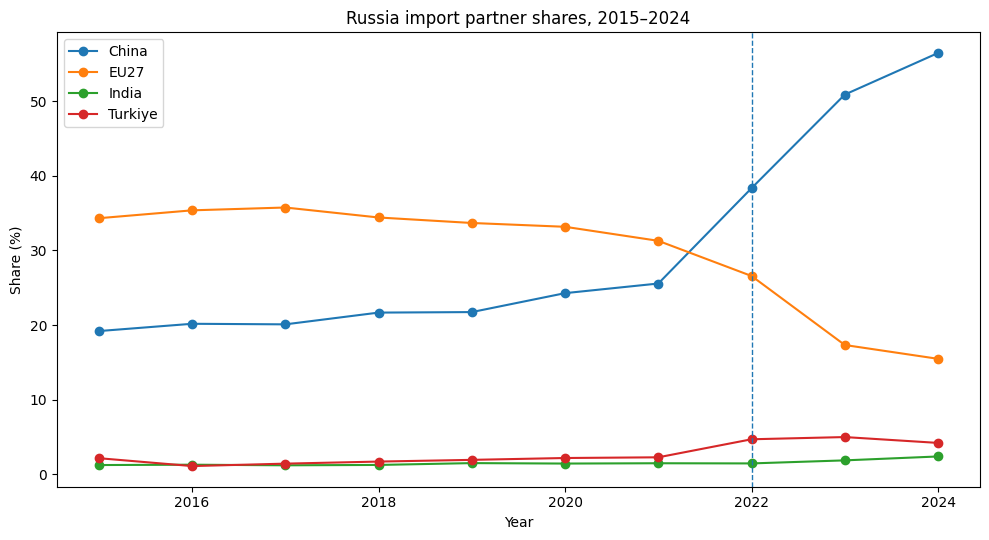

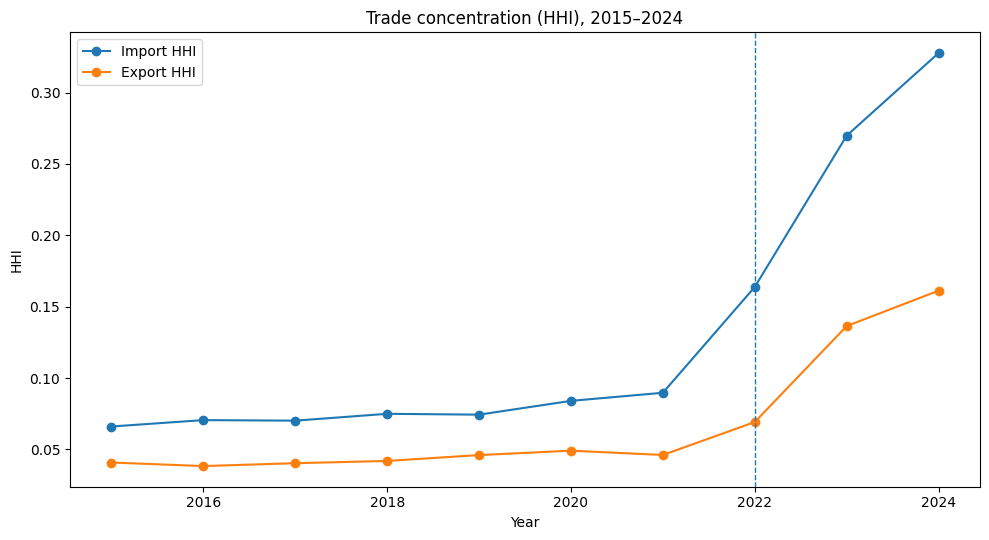

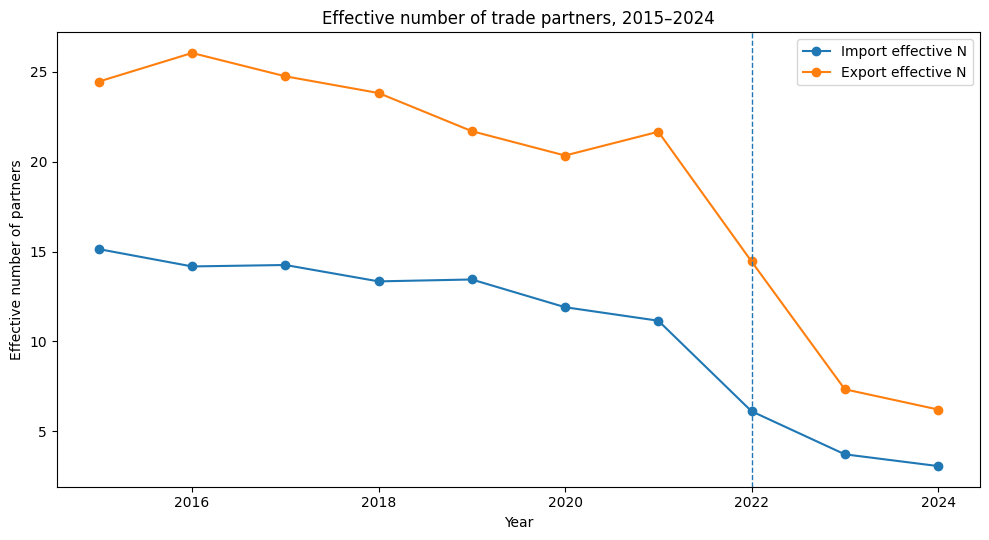

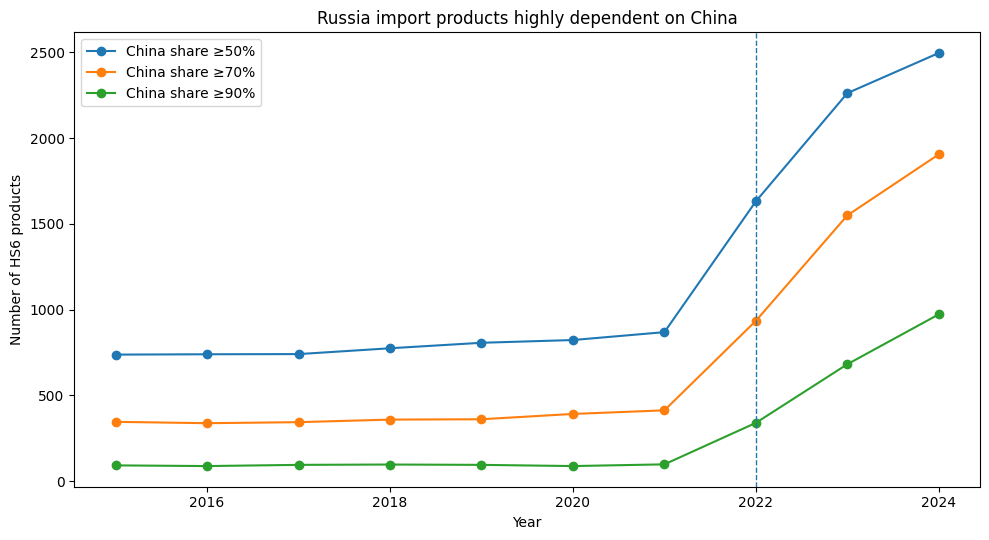

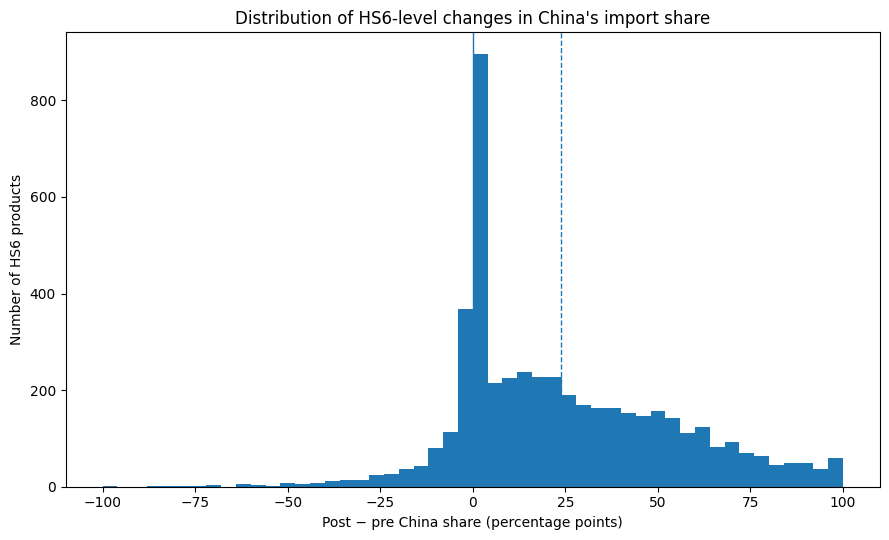

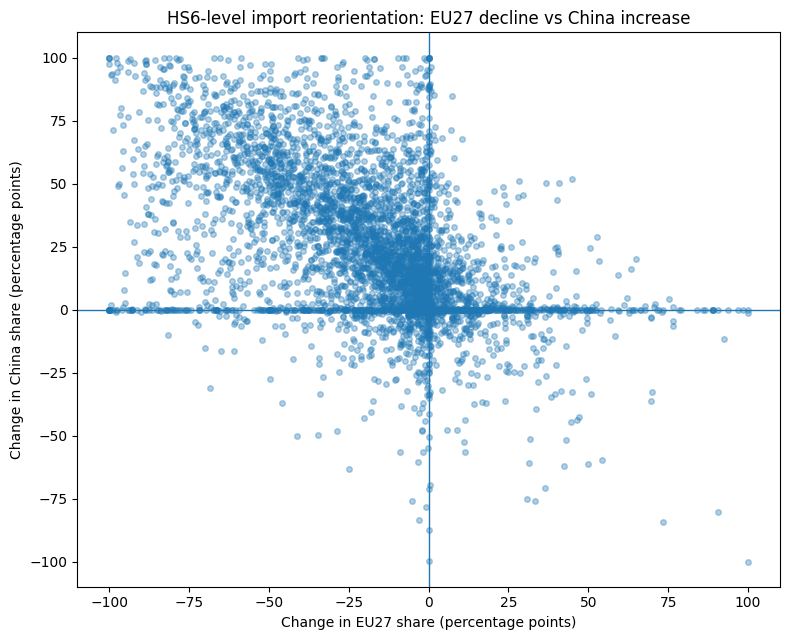

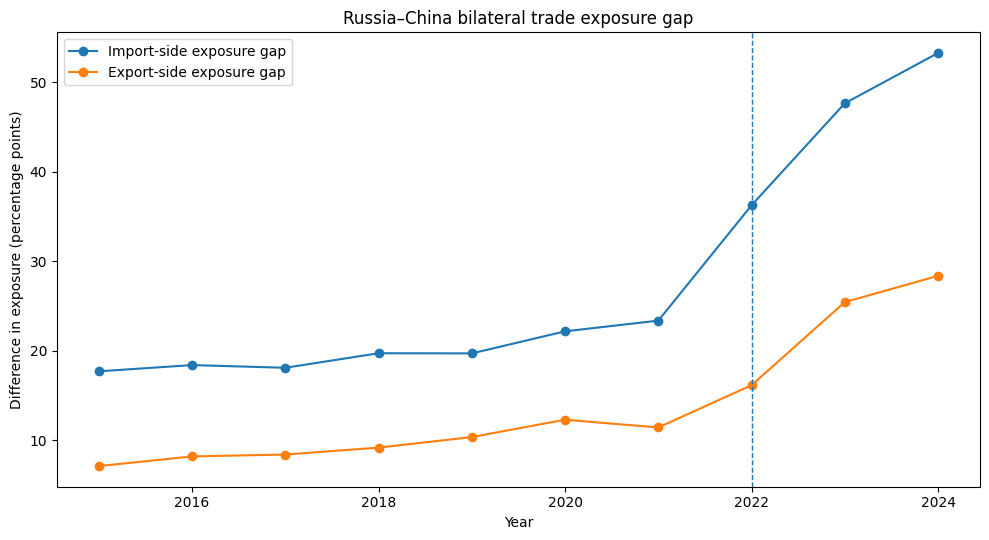

In [10]:
# Figure 1: Import partner shares
plt.figure(figsize=(10,5.5))
for p in ["China","EU27","India","Turkiye"]:
    plt.plot(imp_partner["year"], 100*imp_partner[p], marker="o", label=p)
plt.axvline(2022, linestyle="--", linewidth=1)
plt.xlabel("Year"); plt.ylabel("Share (%)")
plt.title("Russia import partner shares, 2015–2024")
plt.legend()
plt.tight_layout()
plt.savefig(FIG/"Figure1_Import_Partner_Shares.png", dpi=300)
plt.show()

# Figure 2: Concentration
plt.figure(figsize=(10,5.5))
plt.plot(imp_conc["year"], imp_conc["HHI"], marker="o", label="Import HHI")
plt.plot(exp_conc["year"], exp_conc["HHI"], marker="o", label="Export HHI")
plt.axvline(2022, linestyle="--", linewidth=1)
plt.xlabel("Year"); plt.ylabel("HHI")
plt.title("Trade concentration (HHI), 2015–2024")
plt.legend()
plt.tight_layout()
plt.savefig(FIG/"Figure2_Trade_Concentration_HHI.png", dpi=300)
plt.show()

plt.figure(figsize=(10,5.5))
plt.plot(imp_conc["year"], imp_conc["EffectiveN"], marker="o", label="Import effective N")
plt.plot(exp_conc["year"], exp_conc["EffectiveN"], marker="o", label="Export effective N")
plt.axvline(2022, linestyle="--", linewidth=1)
plt.xlabel("Year"); plt.ylabel("Effective number of partners")
plt.title("Effective number of trade partners, 2015–2024")
plt.legend()
plt.tight_layout()
plt.savefig(FIG/"Figure2b_Effective_Number_of_Partners.png", dpi=300)
plt.show()

# Figure 3: High dependence counts
plt.figure(figsize=(10,5.5))
plt.plot(dep["year"], dep["china_ge_50"], marker="o", label="China share ≥50%")
plt.plot(dep["year"], dep["china_ge_70"], marker="o", label="China share ≥70%")
plt.plot(dep["year"], dep["china_ge_90"], marker="o", label="China share ≥90%")
plt.axvline(2022, linestyle="--", linewidth=1)
plt.xlabel("Year"); plt.ylabel("Number of HS6 products")
plt.title("Russia import products highly dependent on China")
plt.legend()
plt.tight_layout()
plt.savefig(FIG/"Figure3_High_Dependence_HS6_Counts.png", dpi=300)
plt.show()

# Figure 4: HS6 distribution of China share changes
delta = imp_pp["delta_china_share"].dropna()
plt.figure(figsize=(9,5.5))
plt.hist(100*delta, bins=50)
plt.axvline(0, linewidth=1)
plt.axvline(100*delta.mean(), linestyle="--", linewidth=1)
plt.xlabel("Post − pre China share (percentage points)")
plt.ylabel("Number of HS6 products")
plt.title("Distribution of HS6-level changes in China's import share")
plt.tight_layout()
plt.savefig(FIG/"Figure4_HS6_China_Share_Change_Distribution.png", dpi=300)
plt.show()

# Figure 5: China vs EU scatter
plt.figure(figsize=(8,6.5))
plt.scatter(100*d_corr["delta_eu27_share"], 100*d_corr["delta_china_share"], alpha=.35, s=16)
plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)
plt.xlabel("Change in EU27 share (percentage points)")
plt.ylabel("Change in China share (percentage points)")
plt.title("HS6-level import reorientation: EU27 decline vs China increase")
plt.tight_layout()
plt.savefig(FIG/"Figure5_HS6_EU_vs_China_Scatter.png", dpi=300)
plt.show()

# Figure 6: Bilateral exposure gap (optional but useful)
gap_imp = gap[gap.direction.eq("ImportSide")].copy()
gap_exp = gap[gap.direction.eq("ExportSide")].copy()
plt.figure(figsize=(10,5.5))
plt.plot(gap_imp["year"], 100*gap_imp["Difference"], marker="o", label="Import-side exposure gap")
plt.plot(gap_exp["year"], 100*gap_exp["Difference"], marker="o", label="Export-side exposure gap")
plt.axvline(2022, linestyle="--", linewidth=1)
plt.xlabel("Year"); plt.ylabel("Difference in exposure (percentage points)")
plt.title("Russia–China bilateral trade exposure gap")
plt.legend()
plt.tight_layout()
plt.savefig(FIG/"Figure6_Bilateral_Exposure_Gap.png", dpi=300)
plt.show()


## 5. Save tables, figures, and final workbook

In [11]:
# Save tables
imp_partner.to_csv(TAB/"T1_import_partner_shares.csv", index=False)
exp_partner.to_csv(TAB/"T1_export_partner_shares.csv", index=False)
t1.to_csv(TAB/"T1_prepost_summary.csv", index=False)

imp_conc.to_csv(TAB/"T2_import_concentration_by_year.csv", index=False)
exp_conc.to_csv(TAB/"T2_export_concentration_by_year.csv", index=False)
t2.to_csv(TAB/"T2_concentration_summary.csv", index=False)

t3.to_csv(TAB/"T3_china_specificity.csv", index=False)

dep.to_csv(TAB/"T4_HS6_dependence_by_year.csv", index=False)
t4.to_csv(TAB/"T4_HS6_dependence_prepost.csv", index=False)

t5.to_csv(TAB/"T5_nonenergy_prepost.csv", index=False)

annual_energy.to_csv(TAB/"T6_annual_energy_to_china.csv", index=False)
t6.to_csv(TAB/"T6_crude_oil_value_quantity.csv", index=False)

gap.to_csv(TAB/"T7_exposure_gap_by_year.csv", index=False)
t7.to_csv(TAB/"T7_exposure_gap_prepost.csv", index=False)

breaks.to_csv(TAB/"T8_break_screening.csv", index=False)
t8_best.to_csv(TAB/"T8_best_breaks.csv", index=False)

imp_pp.to_csv(TAB/"HS6_import_prepost_changes.csv", index=False)
exp_pp.to_csv(TAB/"HS6_export_prepost_changes.csv", index=False)
hs6_stats.to_csv(TAB/"HS6_statistical_tests.csv", index=False)
nonenergy_stats.to_csv(TAB/"HS6_nonenergy_statistical_tests.csv", index=False)
corr.to_csv(TAB/"China_EU_change_correlation.csv", index=False)

# Final audit
audit_rows = []
audit_rows.append(["Import China share change (pp)", float(t1[(t1.side=='Import') & (t1.partner=='China')]['change_pp'].iloc[0])])
audit_rows.append(["Import HHI growth (%)", float(t2[(t2.side=='Import') & (t2.metric=='HHI')]['growth_pct'].iloc[0])])
audit_rows.append(["HS6 China>=50 count growth (%)", float(t4[t4.metric=='china_ge_50']['growth_pct'].iloc[0])])
audit_rows.append(["HS6 China>=70 count growth (%)", float(t4[t4.metric=='china_ge_70']['growth_pct'].iloc[0])])
audit_rows.append(["HS6 China>=90 count growth (%)", float(t4[t4.metric=='china_ge_90']['growth_pct'].iloc[0])])
audit_rows.append(["Non-energy import China change (pp)", float(t5[(t5.side=='Import_nonenergy') & (t5.partner=='China')]['change_pp'].iloc[0])])
audit_rows.append(["Crude oil quantity growth (%)", float(t6['quantity_growth_pct'].iloc[0])])
audit_rows.append(["HS6 import China mean change (pp)", float(hs6_stats[hs6_stats.outcome=='Import: China share']['mean_change_pp'].iloc[0])])
audit_rows.append(["HS6 import EU mean change (pp)", float(hs6_stats[hs6_stats.outcome=='Import: EU27 share']['mean_change_pp'].iloc[0])])
audit = pd.DataFrame(audit_rows, columns=["Metric","FinalValue"])
audit.to_csv(TAB/"FINAL_CONSISTENCY_AUDIT.csv", index=False)

# Workbook
xlsx = OUT / "Russia_Trade_Master_Final_Results.xlsx"
with pd.ExcelWriter(xlsx, engine="openpyxl") as w:
    t1.to_excel(w, sheet_name="T1_partner", index=False)
    t2.to_excel(w, sheet_name="T2_concentration", index=False)
    t3.to_excel(w, sheet_name="T3_specificity", index=False)
    dep.to_excel(w, sheet_name="T4_dependence_year", index=False)
    t4.to_excel(w, sheet_name="T4_dependence_prepost", index=False)
    t5.to_excel(w, sheet_name="T5_nonenergy", index=False)
    annual_energy.to_excel(w, sheet_name="T6_energy_year", index=False)
    t6.to_excel(w, sheet_name="T6_crude_summary", index=False)
    t7.to_excel(w, sheet_name="T7_exposure_gap", index=False)
    t8_best.to_excel(w, sheet_name="T8_best_breaks", index=False)
    hs6_stats.to_excel(w, sheet_name="HS6_stats", index=False)
    nonenergy_stats.to_excel(w, sheet_name="HS6_nonenergy_stats", index=False)
    corr.to_excel(w, sheet_name="China_EU_corr", index=False)
    audit.to_excel(w, sheet_name="Final_audit", index=False)

# Metadata
metadata = {
    "input_priority": ["Russia_BACI_Lite_Dataset.zip", "BACI_HS12_V202601.zip"],
    "source_used": str(lite_zip),
    "years": YEARS,
    "pre": PRE,
    "adjustment_year": ADJUSTMENT_YEAR,
    "post": POST,
    "design": "non-causal structural empirical analysis",
    "outputs": {
        "tables_dir": str(TAB),
        "figures_dir": str(FIG),
        "excel": str(xlsx.name)
    }
}
with open(OUT/"analysis_metadata.json","w",encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

# Zip everything
zip_out = ROOT / "Russia_Trade_Master_Final_Outputs.zip"
if zip_out.exists():
    zip_out.unlink()
shutil.make_archive(str(zip_out.with_suffix("")), "zip", OUT)

print("Excel:", xlsx)
print("ZIP:", zip_out)

try:
    from google.colab import files
    files.download(str(zip_out))
except Exception:
    pass


Excel: /content/russia_trade_master/outputs/Russia_Trade_Master_Final_Results.xlsx
ZIP: /content/russia_trade_master/Russia_Trade_Master_Final_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>